In [34]:
!pip3 install numpy matplotlib opencv-python

In [35]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
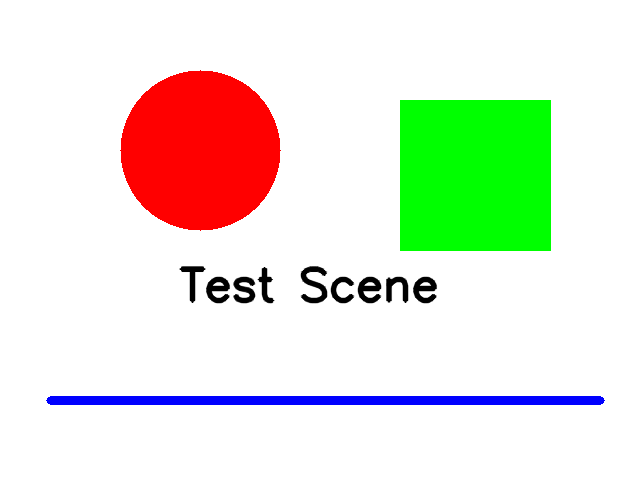

In [36]:
# Image size
w, h = 640, 480

# Create blank white image
img = np.ones((h, w, 3), dtype=np.uint8) * 255

# Draw synthetic shapes
cv2.circle(img, (200, 150), 80, (255, 0, 0), -1)      # blue circle
cv2.rectangle(img, (400, 100), (550, 250), (0, 255, 0), -1) # green rectangle
cv2.line(img, (50, 400), (600, 400), (0, 0, 255), 8)  # red line
cv2.putText(img, "Test Scene", (180, 300), cv2.FONT_HERSHEY_SIMPLEX,
            1.5, (0,0,0), 3, cv2.LINE_AA)

In [52]:
# Camera intrinsics
fx, fy = 800, 800
cx, cy = w // 2, h // 2
K = np.array([[fx, 0, cx],
              [0, fy, cy],
              [0, 0, 1]], dtype=np.float32)

# Distortion coefficients (strong)
dist_coeffs = np.array([-0.6, 0.3, 0.01, 0.01, -0.2], dtype=np.float32)

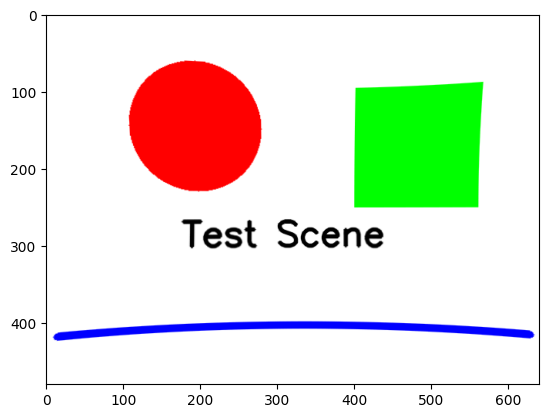

In [54]:
# Create mapping to APPLY distortion
map1, map2 = cv2.initUndistortRectifyMap(K, dist_coeffs, np.eye(3), K, (w, h), cv2.CV_32FC1)
distorted = cv2.remap(img, map1, map2, interpolation=cv2.INTER_LINEAR)

# Show results
plt.imshow(np.array(distorted))

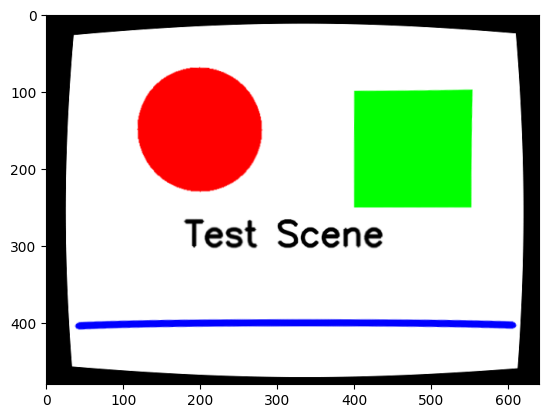

In [56]:
# Undistort the image
undistorted = cv2.undistort(distorted, K, -dist_coeffs)
plt.imshow(np.array(undistorted))